# Basics of Mobile Robotics - Project

#### Students:
ADD NAMES

In [ ]:
%reload_ext autoreload
%autoreload 2

import sys
import tdmclient.notebook
from tdmclient import ClientAsync, aw

import src.filtering
import src.global_navigation
import src.local_navigation
import src.vision
# from src.robot import Robot

#### Connect to and define functions

In [31]:
await tdmclient.notebook.start()
print("Connected to Thymio")

Connected to Thymio


In [32]:
@tdmclient.notebook.sync_var
def robot_set_speed(left, right):
    global motor_left_target, motor_right_target
    motor_left_target = left
    motor_right_target = right

@tdmclient.notebook.sync_var
def robot_stop():
    global motor_left_target,motor_right_target
    motor_left_target = 0
    motor_right_target = 0
    
@tdmclient.notebook.sync_var
def robot_get_speed():
    global motor_left_speed, motor_right_speed
    return motor_left_speed, motor_right_speed
    
@tdmclient.notebook.sync_var
def robot_get_ir():
    global prox_horizontal
    return prox_horizontal.copy()

@tdmclient.notebook.sync_var
def robot_get_acc():
    global acc
    return acc

In [33]:
%%run_python



In [36]:
# Sample IR fast:
import time

count = 0
robot_set_speed(50, 50)

start = time.time()

while count < 25:
    speed = robot_get_speed()
    ir = robot_get_ir()
    print(f"Speed: ", speed)
    print(f"IR at time {(time.time() - start):.2f}: ", ir)
    count = count + 1
    time.sleep(0.2)

Speed:  (0, 0)
IR at time 0.00:  [1508, 2208, 2030, 1875, 0, 4778, 4528]
Speed:  (0, 0)
IR at time 0.20:  [0, 1835, 1593, 0, 0, 4779, 4530]
Speed:  (31, 35)
IR at time 0.41:  [1508, 2208, 2030, 1875, 0, 4778, 4528]
Speed:  (47, 47)
IR at time 0.61:  [0, 1984, 1709, 0, 0, 4776, 4531]
Speed:  (47, 47)
IR at time 0.82:  [0, 1984, 1709, 0, 0, 4776, 4531]
Speed:  (50, 54)
IR at time 1.02:  [1801, 2357, 2141, 2070, 0, 4781, 4532]
Speed:  (48, 42)
IR at time 1.23:  [0, 1848, 1552, 0, 0, 4774, 4528]
Speed:  (51, 45)
IR at time 1.43:  [4079, 3447, 3409, 4367, 3640, 4767, 4524]
Speed:  (51, 48)
IR at time 1.63:  [0, 1762, 1439, 0, 0, 4781, 4532]
Speed:  (48, 50)
IR at time 1.84:  [4261, 3554, 3470, 4342, 3642, 4770, 4525]
Speed:  (50, 50)
IR at time 2.04:  [0, 1735, 1402, 0, 0, 4724, 4522]
Speed:  (50, 50)
IR at time 2.25:  [0, 1735, 1402, 0, 0, 4724, 4522]
Speed:  (50, 49)
IR at time 2.45:  [2637, 2672, 2459, 2697, 0, 4773, 4526]
Speed:  (52, 49)
IR at time 2.65:  [3186, 2895, 2781, 3344, 0, 47

In [37]:
robot_stop()

#### Create robot, pass functions and test

In [5]:
robot = Robot(robot_set_speed, robot_stop, robot_get_speed, robot_get_ir, robot_get_acc)

In [6]:
vs, pos, Ps = robot.try_kalman()

Predict step with v: 0.0, w: 0.0, dt: 0.2


IndexError: index 3 is out of bounds for axis 0 with size 3

In [7]:
robot.stop()

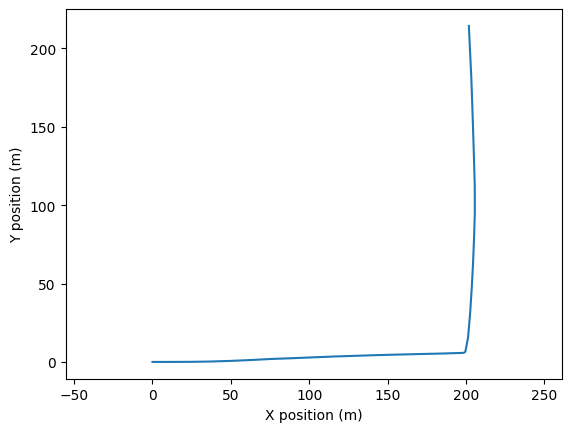

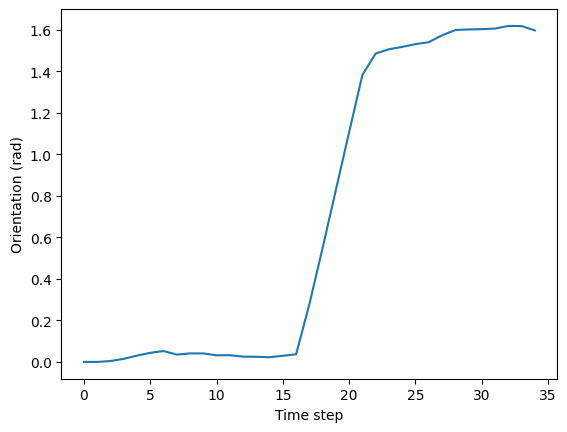

In [66]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot([p[0] for p in pos], [p[1] for p in pos], label='Estimated Path')
plt.axis('equal')
plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.show()

plt.figure()
plt.plot([p[2] for p in pos], label='Estimated Orientation')
plt.xlabel('Time step')
plt.ylabel('Orientation (rad)')
plt.show()


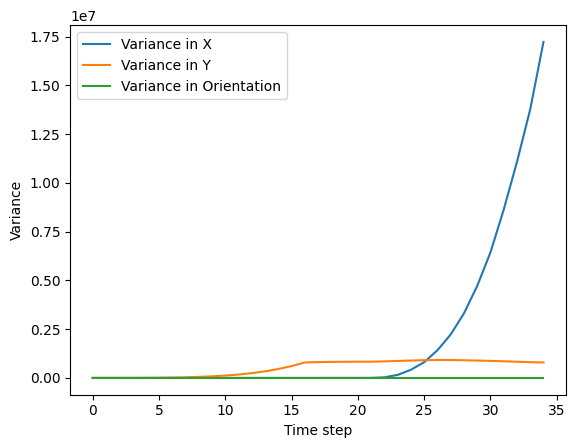

In [70]:
plt.figure()
plt.plot([P[0,0] for P in Ps], label='Variance in X')
plt.plot([P[1,1] for P in Ps], label='Variance in Y')
plt.plot([P[2,2] for P in Ps], label='Variance in Orientation')
plt.xlabel('Time step')
plt.ylabel('Variance')
plt.legend()
plt.show()

#### Create other classes

In [ ]:
kalman = filtering.ExtendedKalmanFilter()
vision = vision.Vision()
global_nav = global_navigation.GlobalNavigation()
local_nav = local_navigation.LocalNavigation()

#### Disconnect robot

In [25]:
# TODO:
await tdmclient.notebook.stop()
print("Disconnected from Thymio")

Disconnected from Thymio
